# A/B-тест механики «Опыт владельцев»: дизайн, размер выборки, правило решения

Тест должен измерить главную непроверенную гипотезу модели — **прирост конверсии в сделку** (сценарии: 4% / 5% / 8%) — и сказать, продолжать, менять или закрывать механику. Порог окупаемости базы по модели лежит внутри вилки, поэтому решение зависит от результата теста.

## Дизайн
| Параметр | Решение |
|---|---|
| Единица рандомизации | **Пользователь** (хэш `user_id`), 50/50. Не карточка: иначе покупатель перетекает между карточками и эффект завышается |
| Кто участвует | Пользователи, открывшие карточку модели с **заполненным блоком** (5+ отзывов) в пилотных категориях |
| Контроль / тест | Карточка без блока / с блоком (отзывы, ответы владельцев, «Можно продать») |
| Главная метрика | Доля пользователей со сделкой через Доставку за 14 дней после первого показа (относительный прирост) |
| Метрики-ограничители | Контакты с продавцами на пользователя (не падают более чем на 1%), доля жалоб на отзывы, время ответа модерации |
| Вторичные | Отзывы, ответы в обсуждениях, выставленные вещи через «Можно продать» |
| Срезы | По числу отзывов на странице модели (0 / 1–4 / 5+), по категории |
| Длительность | Не меньше 2 полных недель набора + 14 дней окно наблюдения; решение — один раз, по окончании (без подглядывания) |
| Проверки | SRM (баланс групп), эффект новизны (неделя 1 против недель 3+) |

**Связь с моделью.** Тест считается на уровне пользователя, поэтому измеряет *чистый* эффект — уже с учётом перетока сделок. В модели ему соответствует величина `x = прирост × доля инкрементальных − потери`.

In [1]:
%pip install -q numpy pandas openpyxl matplotlib plotly scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, math, warnings
import numpy as np, pandas as pd, openpyxl
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.stats import norm, chi2

warnings.filterwarnings('ignore')
XLSX = 'Avito_finmodel_Opyt_vladeltsev_tochno.xlsx'
OUT = 'charts_ab'; os.makedirs(OUT, exist_ok=True)
SC = ['Пессимист', 'База', 'Оптимист']
COLORS = {'Пессимист': '#D55E00', 'База': '#0072B2', 'Оптимист': '#009E73'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'figure.dpi': 110, 'axes.titleweight': 'bold'})
FIGS = {}

def pshow(fig, name, title, h=480):
    fig.update_layout(template='plotly_white', title=dict(text=title, x=0.01), font=dict(family='Arial', size=13), height=h, margin=dict(l=60, r=30, t=80, b=60), legend=dict(orientation='h', y=-0.2))
    FIGS[name] = fig; fig.write_html(f'{OUT}/{name}.html', include_plotlyjs='cdn'); fig.show()

def mshow(fig, name):
    fig.tight_layout(); fig.savefig(f'{OUT}/{name}_static.png', dpi=200, bbox_inches='tight'); plt.show()

## 1. Что берём из финмодели

In [3]:
wb = openpyxl.load_workbook(XLSX, data_only=True)
def get(sc, label):
    ws = wb[f'Модель_{sc}']
    r = next(r for r in range(1, ws.max_row + 1) if ws.cell(r, 1).value == label)
    return ws.cell(r, 3).value

LB = {'uplift': 'Прирост конверсии в сделку в карточках с блоком (относительный)', 'incr': 'Доля прироста, действительно инкрементальная',
      'neg': 'Негативный эффект: потеря сделок в охваченных карточках (слабые модели, меньше контактов)', 'x': 'Чистый эффект на конверсию (uplift × доля инкрем. − потери)',
      'be': 'Мин. прирост конверсии: простая окупаемость за 12 кв.', 'bed': 'Мин. прирост конверсии: дисконтированная окупаемость за 12 кв.',
      'cum': 'Накопленный чистый поток за 3 года', 'npv': 'NPV за 3 года', 'M1': 'Маржинальный доход эффекта 1 за 3 года', 'M1d': 'Маржинальный доход эффекта 1, дисконтированный'}
M = pd.DataFrame({s: {k: get(s, v) for k, v in LB.items()} for s in SC}).T.astype(float)

# Порог на уровне пользователя: x = uplift × incr − neg  =>  uplift_min × incr − neg
M['x_be'] = M['be'] * M['incr'] - M['neg']          # простая окупаемость за 12 кв.
M['x_bed'] = M['bed'] * M['incr'] - M['neg']        # дисконтированная
M.round(4)

,uplift,incr,neg,x,be,bed,cum,npv,M1,M1d,x_be,x_bed
Пессимист,0.04,0.65,0.0050,0.0210,0.3882,0.4269,-478.1100,-381.4398,44.3634,31.8477,0.2473,0.2725
База,0.05,0.75,0.0030,0.0345,0.0605,0.0645,-106.3881,-106.5007,465.7398,338.7592,0.0424,0.0453
Оптимист,0.08,0.85,0.0015,0.0665,0.0285,0.0311,1029.2177,714.1778,1564.4602,1141.7212,0.0228,0.0249


Значения `x` — это то, что тест должен измерить на уровне пользователя. Для **базы**: ожидаемый чистый эффект `x` ниже порога окупаемости `x_be`, то есть при 5% проект на грани, и тест нужен, чтобы понять, по какую сторону порога мы окажемся.

## 2. Допущения теста (проверить с аналитиками Авито)
Исходных данных об Авито у меня нет, эти числа — **параметры-заглушки**; от них зависит только длительность и размер выборки, не логика.

In [4]:
P0 = 0.03            # доля пользователей со сделкой через Доставку за 14 дней среди увидевших карточку в пилотных категориях (ДОПУЩЕНИЕ)
ALPHA, POWER = 0.05, 0.80
DAILY_NEW = 300_000  # новых пользователей в день, впервые увидевших карточку с заполненным блоком в пилотных категориях (ДОПУЩЕНИЕ)
WINDOW_DAYS, MIN_WEEKS = 14, 2
RHO = 0.30           # корреляция «сделки до теста» и «сделки в тесте» для CUPED (ДОПУЩЕНИЕ, уточнить по истории)
CONTACT_P0, NI_MARGIN = 0.25, 0.01   # доля пользователей, написавших продавцу; допустимое падение контактов — 1%
Z_A, Z_B = norm.ppf(1 - ALPHA / 2), norm.ppf(POWER)

def n_per_arm(p0, rel_lift, var_reduction=0.0):
    """Пользователей в каждой группе для двусторонней проверки долей (z-тест) при относительном приросте rel_lift."""
    p1 = p0 * (1 + rel_lift)
    n = (Z_A + Z_B) ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / (p1 - p0) ** 2
    return math.ceil(n * (1 - var_reduction))

def duration_days(n):
    enroll = max(math.ceil(2 * n / DAILY_NEW), MIN_WEEKS * 7)
    return enroll + WINDOW_DAYS

x_be = M.loc['База', 'x_be']
print(f"Порог окупаемости базы на уровне пользователя: {x_be:.2%}")
print(f"Выборка для обнаружения порога: {n_per_arm(P0, x_be):,} пользователей в группе, срок ≈ {duration_days(n_per_arm(P0, x_be))} дней")

Порог окупаемости базы на уровне пользователя: 4.24%
Выборка для обнаружения порога: 288,381 пользователей в группе, срок ≈ 28 дней


## 3. Размер выборки: от чего зависит

,2%,3%,x базы 3.5%,порог базы 4.2%,x оптимиста 6.7%
Базовая доля сделок,,,,,
1%,"3,923,648","1,752,386","1,327,962","883,379","362,982"
2%,"1,941,805","867,207","657,155","437,131","179,594"
3%,"1,281,191","572,147","433,553","288,381","118,465"
5%,"752,700","336,099","254,672","169,382","69,562"


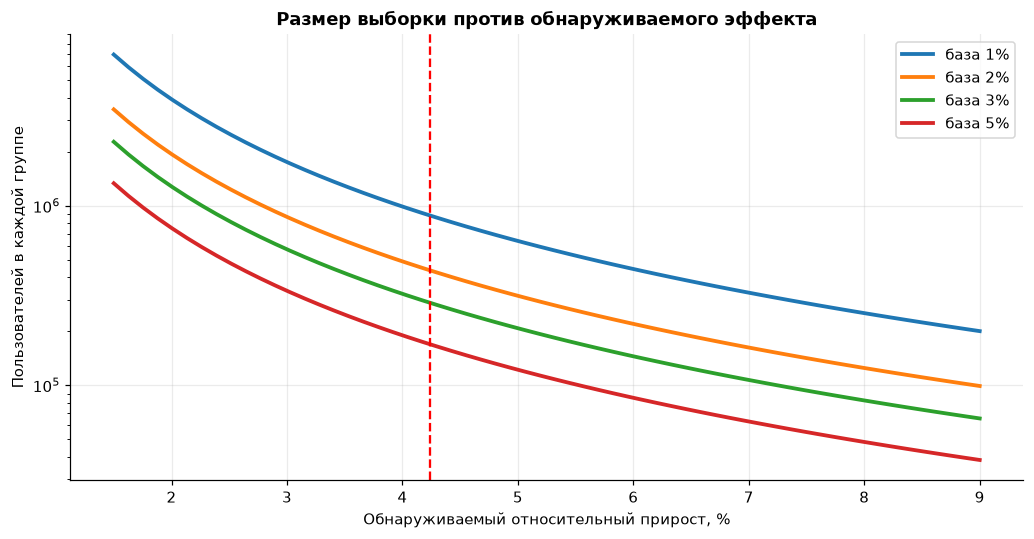

In [5]:
LIFTS = [0.02, 0.03, M.loc['База', 'x'], x_be, M.loc['Оптимист', 'x']]
LAB = ['2%', '3%', f"x базы {M.loc['База', 'x']:.1%}", f"порог базы {x_be:.1%}", f"x оптимиста {M.loc['Оптимист', 'x']:.1%}"]
rows = []
for p0 in [0.01, 0.02, 0.03, 0.05]:
    rows.append([f'{p0:.0%}'] + [f'{n_per_arm(p0, l):,}' for l in LIFTS])
tbl = pd.DataFrame(rows, columns=['Базовая доля сделок'] + LAB).set_index('Базовая доля сделок')
display(tbl)

grid = np.linspace(0.015, 0.09, 60)
fig = go.Figure()
for p0 in [0.01, 0.02, 0.03, 0.05]:
    fig.add_scatter(x=grid * 100, y=[n_per_arm(p0, g) for g in grid], mode='lines', name=f'база {p0:.0%}', line=dict(width=3))
fig.add_vline(x=x_be * 100, line=dict(color='red', dash='dash'), annotation_text='порог окупаемости базы')
fig.update_yaxes(type='log', title='Пользователей в каждой группе'); fig.update_xaxes(title='Обнаруживаемый относительный прирост, %')
pshow(fig, 'sample_size', 'Размер выборки против обнаруживаемого эффекта (α = 5%, мощность 80%)')

f, ax = plt.subplots(figsize=(9.5, 5))
for p0 in [0.01, 0.02, 0.03, 0.05]: ax.plot(grid * 100, [n_per_arm(p0, g) for g in grid], lw=2.5, label=f'база {p0:.0%}')
ax.axvline(x_be * 100, color='red', ls='--'); ax.set_yscale('log'); ax.set_xlabel('Обнаруживаемый относительный прирост, %'); ax.set_ylabel('Пользователей в каждой группе')
ax.set_title('Размер выборки против обнаруживаемого эффекта'); ax.legend(); mshow(f, 'sample_size')

**Вывод по выборке.** Чем ниже базовая доля сделок и чем меньше эффект, тем больше пользователей нужно. Если окажется, что набор идёт медленнее (DAILY_NEW), срок теста растёт, но не логика. Для категорий с малым трафиком эффект стоит оценивать на объединённой выборке и смотреть срезы только как исследовательские.

## 4. Правило решения и мощность: что получится при разных истинных эффектах

Решающее правило фиксируем **до** теста, по 95% доверительному интервалу относительного прироста `L` (чистый эффект на пользователя):

* **Продолжить** — нижняя граница интервала `> 0` и оценка `L ≥ x_be` (эффект реален и не ниже порога окупаемости).
* **Закрыть** — верхняя граница `< x_be` (даже оптимистичная оценка не доходит до окупаемости).
* **Изменить / продлить** — всё остальное (эффект есть, но не доказано, что он выше порога).

Симулируем тест при истинных эффектах из сценариев модели и при нулевом. Размер выборки — тот, что нужен для порога (1×), и вдвое больший (2×).

In [6]:
rng = np.random.default_rng(2026)

def simulate(n, true_lift, p0=P0, sims=5000, thr=x_be):
    s0 = rng.binomial(n, p0, sims); s1 = rng.binomial(n, p0 * (1 + true_lift), sims)
    ok = (s0 > 0) & (s1 > 0); s0, s1 = s0[ok], s1[ok]
    lr = np.log(s1 / s0); se = np.sqrt(1 / s1 - 1 / n + 1 / s0 - 1 / n)
    lo, hi, est = np.exp(lr - Z_A * se) - 1, np.exp(lr + Z_A * se) - 1, np.exp(lr) - 1
    go_, stop = (lo > 0) & (est >= thr), hi < thr
    return go_.mean(), (~go_ & ~stop).mean(), stop.mean()

TRUTH = {'Нулевой эффект': 0.0, f"Пессимист ({M.loc['Пессимист', 'x']:.1%})": M.loc['Пессимист', 'x'], f"База ({M.loc['База', 'x']:.1%})": M.loc['База', 'x'],
         f"Порог базы ({x_be:.1%})": x_be, f"Оптимист ({M.loc['Оптимист', 'x']:.1%})": M.loc['Оптимист', 'x']}
n1 = n_per_arm(P0, x_be)
res = {}
for mult in (1, 2):
    res[mult] = pd.DataFrame({k: simulate(n1 * mult, v) for k, v in TRUTH.items()}, index=['Продолжить', 'Изменить / продлить', 'Закрыть']).T
for mult in (1, 2):
    print(f'Выборка {mult}× ({n1 * mult:,} в группе):'); display((res[mult] * 100).round(0).astype(int).astype(str) + '%')

Выборка 1× (288,381 в группе):


,Продолжить,Изменить / продлить,Закрыть
Нулевой эффект,0%,21%,79%
Пессимист (2.1%),8%,63%,28%
База (3.5%),32%,60%,8%
Порог базы (4.2%),49%,48%,3%
Оптимист (6.7%),94%,6%,0%


Выборка 2× (576,762 в группе):


,Продолжить,Изменить / продлить,Закрыть
Нулевой эффект,0%,2%,98%
Пессимист (2.1%),2%,47%,50%
База (3.5%),23%,65%,12%
Порог базы (4.2%),50%,47%,3%
Оптимист (6.7%),98%,2%,0%


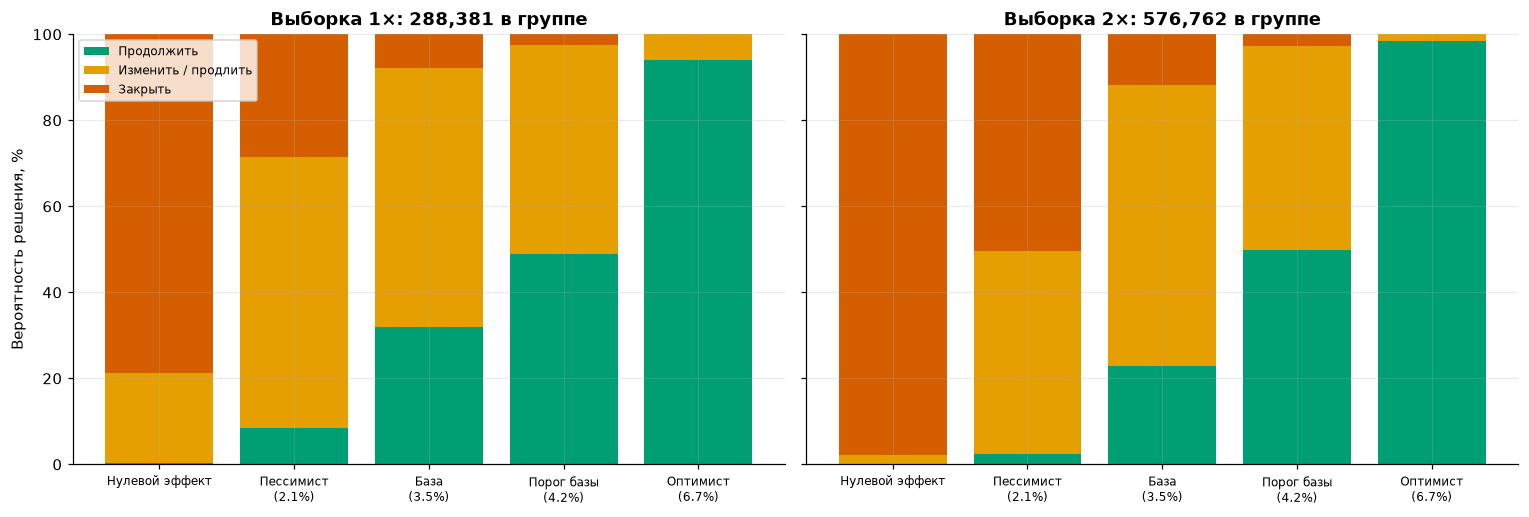

In [7]:
DCOL = {'Продолжить': '#009E73', 'Изменить / продлить': '#E69F00', 'Закрыть': '#D55E00'}
fig = go.Figure()
for mult, dash in ((1, None), (2, None)):
    d = res[mult]
    for c in d.columns:
        fig.add_bar(x=[f'{k} | {mult}×' for k in d.index], y=d[c] * 100, name=c, marker_color=DCOL[c], showlegend=(mult == 1), legendgroup=c)
fig.update_layout(barmode='stack'); fig.update_yaxes(title='Вероятность решения, %')
pshow(fig, 'decision_probs', 'Вероятность решения при разных истинных эффектах (выборка 1× и 2×)', h=540)

f, axs = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, mult in zip(axs, (1, 2)):
    d = res[mult] * 100; bot = np.zeros(len(d))
    for c in d.columns: ax.bar(range(len(d)), d[c], bottom=bot, color=DCOL[c], label=c); bot += d[c].values
    ax.set_xticks(range(len(d)), [k.replace(' (', '\n(') for k in d.index], fontsize=8); ax.set_title(f'Выборка {mult}×: {n1 * mult:,} в группе')
axs[0].set_ylabel('Вероятность решения, %'); axs[0].legend(fontsize=8); mshow(f, 'decision_probs')

**Как читать.** При истинном эффекте базы (ниже порога) тест чаще всего даст «Изменить / продлить» — это честный исход. Увеличение выборки делает решения чётче, но не превращает эффект, лежащий рядом с порогом, в однозначный: рядом с порогом решает не размер выборки, а экономика (затраты, охват).

## 5. Анализ результатов теста: готовый код
Функция принимает таблицу пользователей и возвращает все числа для решения. Ниже она проверена на синтетических данных с известным эффектом, включая срезы по числу отзывов, CUPED и проверку метрики-ограничителя.

Ожидаемые колонки: `user_id`, `group` (`control` / `test`), `deal` (0/1 — сделка за 14 дней), `contacts` (0/1 — писал продавцу), `pre_deal` (0/1 — сделка за 14 дней до теста), `review_bucket` (`0`, `1–4`, `5+`).

In [8]:
def rel_lift(yt, yc, alpha=ALPHA):
    """Относительный прирост среднего и его интервал (дельта-метод)."""
    mt, mc = yt.mean(), yc.mean(); vt, vc = yt.var(ddof=1) / len(yt), yc.var(ddof=1) / len(yc)
    lift = mt / mc - 1; se = math.sqrt(vt / mc ** 2 + mt ** 2 * vc / mc ** 4); z = norm.ppf(1 - alpha / 2)
    return lift, lift - z * se, lift + z * se, se

def cuped(df, y, x):
    """Вычитаем из метрики часть, объяснимую поведением до теста: та же оценка, но уже интервал."""
    theta = np.cov(df[y], df[x])[0, 1] / df[x].var(ddof=1)
    return df[y] - theta * (df[x] - df[x].mean()), theta

def analyze_ab(df, thr=x_be, y='deal', pre='pre_deal', contacts='contacts'):
    out = {}
    t, c = df[df.group == 'test'], df[df.group == 'control']
    # 1. SRM: группы должны быть 50/50
    exp = len(df) / 2; srm_p = 1 - chi2.cdf(((len(t) - exp) ** 2 + (len(c) - exp) ** 2) / exp, 1)
    out['SRM p-value (< 0.001 = ошибка рандомизации)'] = round(srm_p, 4)
    # 2. главная метрика, без и с CUPED
    L, lo, hi, se = rel_lift(t[y], c[y]); out['Прирост, оценка'] = L; out['95% интервал'] = (lo, hi)
    adj, theta = cuped(df, y, pre); ta, ca = adj[df.group == 'test'], adj[df.group == 'control']
    Lc, loc_, hic, sec = rel_lift(ta, ca); out['CUPED: оценка и интервал'] = (Lc, (loc_, hic)); out['Сужение интервала от CUPED'] = 1 - sec / se
    # 3. ограничитель: контакты не упали более чем на NI_MARGIN (односторонний тест)
    Lk, lok, hik, sek = rel_lift(t[contacts], c[contacts]); z = (Lk + NI_MARGIN) / sek
    out['Контакты: прирост'] = Lk; out['Контакты не упали > 1% (p)'] = round(1 - norm.cdf(z), 4)
    # 4. решение по правилу
    d = 'Продолжить' if (loc_ > 0 and Lc >= thr) else 'Закрыть' if hic < thr else 'Изменить / продлить'
    out['Порог'] = thr; out['Решение'] = d
    # 5. срезы
    seg = []
    for b, g in df.groupby('review_bucket'):
        l, a, bb, _ = rel_lift(g[g.group == 'test'][y], g[g.group == 'control'][y]); seg.append([b, len(g), l, a, bb])
    out['Срезы'] = pd.DataFrame(seg, columns=['Отзывов на странице', 'Пользователей', 'Прирост', 'Нижняя', 'Верхняя'])
    return out

def synth(n_per_arm, p0=P0, lifts={'0': 0.0, '1–4': 0.04, '5+': 0.09}, shares=(0.5, 0.3, 0.2), seed=11):
    r = np.random.default_rng(seed); n = 2 * n_per_arm
    q = r.beta(0.6, 0.6 * (1 - p0) / p0, n)                        # индивидуальная склонность к покупке
    bucket = r.choice(list(lifts), n, p=shares); g = np.where(np.arange(n) % 2 == 0, 'control', 'test'); r.shuffle(g)
    eff = np.array([lifts[b] for b in bucket]) * (g == 'test')
    return pd.DataFrame({'user_id': np.arange(n), 'group': g, 'review_bucket': bucket,
                         'pre_deal': r.binomial(1, q), 'deal': r.binomial(1, np.minimum(1, q * (1 + eff))),
                         'contacts': r.binomial(1, np.minimum(1, CONTACT_P0 * (0.5 + q / q.mean() * 0.5)))})

df = synth(n1)
R = analyze_ab(df)
true_overall = 0.3 * 0.04 + 0.2 * 0.09
print(f'Истинный средний эффект в синтетике ≈ {true_overall:.1%} (0% / 4% / 9% по срезам)')
print(f"SRM p-value: {R['SRM p-value (< 0.001 = ошибка рандомизации)']:.3f} (меньше 0.001 — ошибка рандомизации)")
print(f"Прирост: {R['Прирост, оценка']:.2%}, 95% интервал [{R['95% интервал'][0]:.2%}; {R['95% интервал'][1]:.2%}]")
print(f"CUPED: {R['CUPED: оценка и интервал'][0]:.2%}, интервал [{R['CUPED: оценка и интервал'][1][0]:.2%}; {R['CUPED: оценка и интервал'][1][1]:.2%}], сужение интервала {R['Сужение интервала от CUPED']:.1%}")
print(f"Контакты: прирост {R['Контакты: прирост']:.2%}, p-value проверки «не упали более чем на 1%»: {R['Контакты не упали > 1% (p)']:.3f}")
print(f"Порог {R['Порог']:.2%} -> решение: {R['Решение']}")
R['Срезы'].assign(**{c: lambda d, c=c: (d[c] * 100).round(1) for c in ['Прирост', 'Нижняя', 'Верхняя']})

Истинный средний эффект в синтетике ≈ 3.0% (0% / 4% / 9% по срезам)
SRM p-value: 1.000 (меньше 0.001 — ошибка рандомизации)
Прирост: 3.23%, 95% интервал [0.22%; 6.24%]
CUPED: 3.08%, интервал [0.09%; 6.08%], сужение интервала 0.3%
Контакты: прирост 0.00%, p-value проверки «не упали более чем на 1%»: 0.014
Порог 4.24% -> решение: Изменить / продлить


,Отзывов на странице,Пользователей,Прирост,Нижняя,Верхняя
0,0,288296,-2.1,-6.2,1.9
1,1–4,173312,8.7,2.9,14.5
2,5+,115154,8.9,1.9,15.8


Срез по числу отзывов нужен, чтобы понять, **где** блок работает: на страницах без отзывов эффекта нет, на заполненных он растёт. Это же напрямую определяет долю карточек с блоком (`card_peak`) в модели, то есть порог наполненности, после которого блок стоит показывать.

## 6. От измеренного эффекта к окупаемости
Модель линейна по приросту конверсии, поэтому измеренный чистый эффект `L` пересчитывается в накопленный поток и NPV за 3 года без повторного прогона модели:

`поток(L) = поток_базы + M1 × (L / x_базы − 1)`, где `M1` — маржинальный доход эффекта 1 за 3 года.

Порог простой окупаемости: 4.24%; дисконтированной: 4.53%


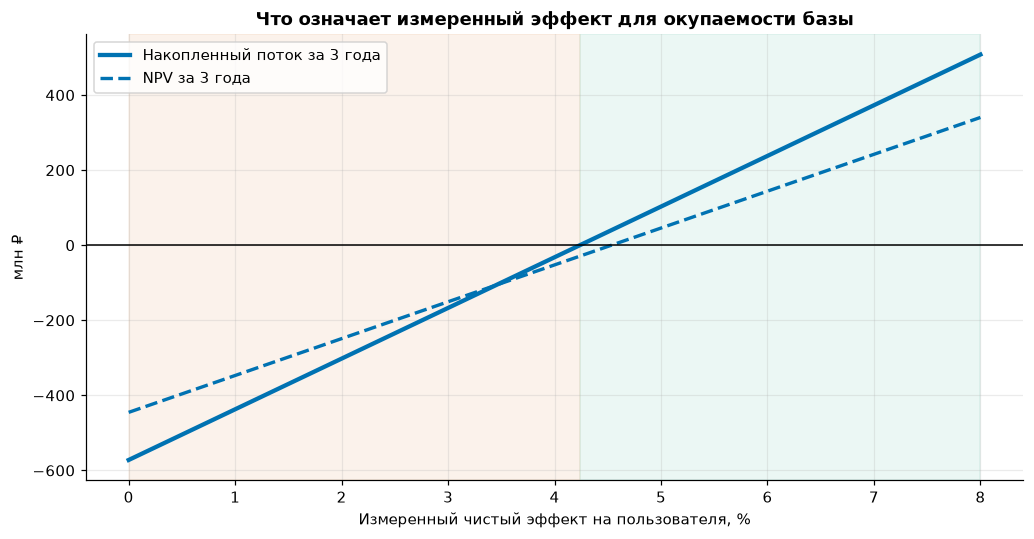

In [9]:
b = M.loc['База']
Ls = np.linspace(0, 0.08, 81)
cum = b['cum'] + b['M1'] * (Ls / b['x'] - 1)
npv = b['npv'] + b['M1d'] * (Ls / b['x'] - 1)
assert abs(b['cum'] + b['M1'] * (b['x_be'] / b['x'] - 1)) < 1e-6          # в точке порога поток равен нулю
print(f"Порог простой окупаемости: {b['x_be']:.2%}; дисконтированной: {b['x_bed']:.2%}")

fig = go.Figure()
fig.add_scatter(x=Ls * 100, y=cum, name='Накопленный поток за 3 года', line=dict(color=COLORS['База'], width=3))
fig.add_scatter(x=Ls * 100, y=npv, name='NPV за 3 года', line=dict(color=COLORS['База'], width=3, dash='dash'))
fig.add_hline(y=0, line=dict(color='black', width=1))
fig.add_vrect(x0=0, x1=b['x_be'] * 100, fillcolor='#D55E00', opacity=0.08, line_width=0, annotation_text='Закрыть / менять', annotation_position='top left')
fig.add_vrect(x0=b['x_be'] * 100, x1=8, fillcolor='#009E73', opacity=0.08, line_width=0, annotation_text='Продолжить', annotation_position='top right')
fig.update_xaxes(title='Измеренный чистый эффект на пользователя, %'); fig.update_yaxes(title='млн ₽')
pshow(fig, 'effect_to_payback', 'Что означает измеренный эффект для окупаемости базы')

f, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(Ls * 100, cum, color=COLORS['База'], lw=2.8, label='Накопленный поток за 3 года'); ax.plot(Ls * 100, npv, color=COLORS['База'], lw=2.2, ls='--', label='NPV за 3 года')
ax.axhline(0, color='black', lw=1); ax.axvspan(0, b['x_be'] * 100, color='#D55E00', alpha=.08); ax.axvspan(b['x_be'] * 100, 8, color='#009E73', alpha=.08)
ax.set_xlabel('Измеренный чистый эффект на пользователя, %'); ax.set_ylabel('млн ₽'); ax.set_title('Что означает измеренный эффект для окупаемости базы'); ax.legend(); mshow(f, 'effect_to_payback')

## 7. Чек-лист запуска
1. Согласовать с аналитикой Авито `P0`, `DAILY_NEW`, `RHO` и пересчитать выборку (раздел 2–3).
2. Зафиксировать правило решения (раздел 4) и порог `x_be` из актуальной версии модели **до** запуска.
3. Выбрать 3–5 пилотных категорий с достаточным числом заполненных страниц моделей (5+ отзывов), иначе тест измерит пустые страницы.
4. Рандомизация по пользователю, проверка SRM в первые 2–3 дня.
5. Не смотреть на результат до конца срока; срезы — только как разведка.
6. По итогам: подставить измеренный `L` в модель (раздел 6) и принять решение по правилу.